COU 07506 — Digital Signal Processing Laboratory

Week: 2
Lab: Lab 1A — Sampling, Aliasing and Quantization
Student Registration Number: 240242411437
Group: 1

Introduction

This laboratory focuses on sampling continuous-time signals and understanding the effects of sampling frequency, aliasing, and quantization in digital signal processing. Python is used to generate, sample, plot, and analyze signals.

## Task 2.1 — Aliasing of a sinusoid

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
import os

plt.rcParams["figure.figsize"] = (9, 3.5)

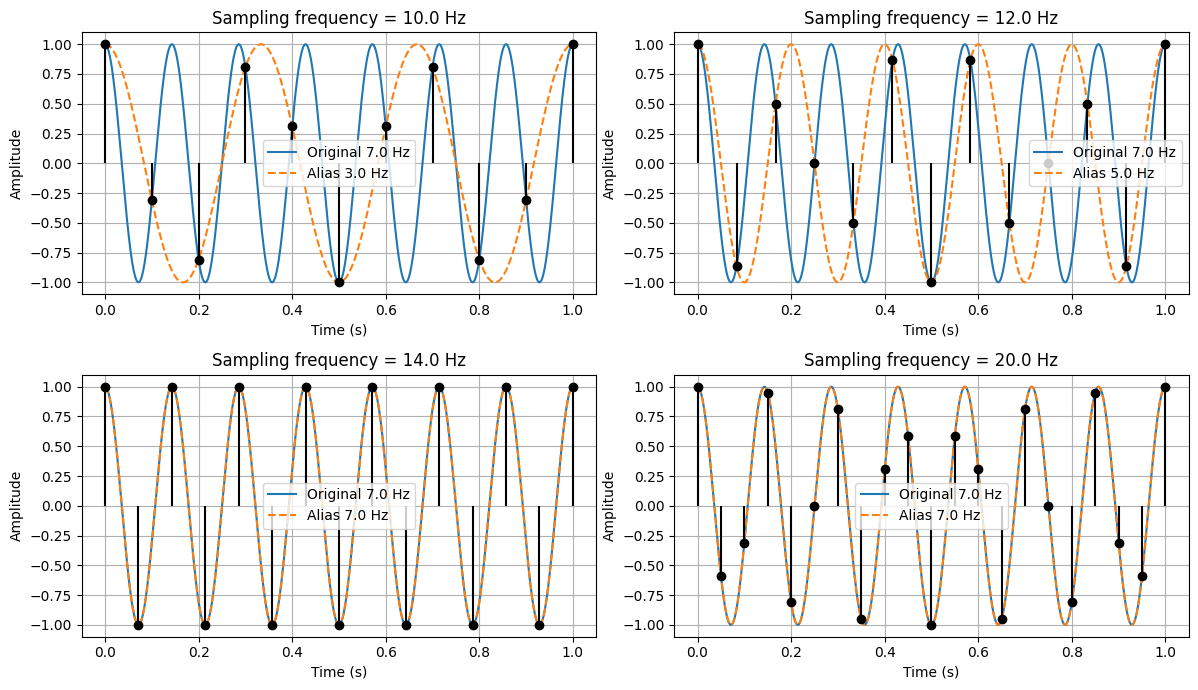

In [18]:
f0 = 7.0
sampling_rates = [10.0, 12.0, 14.0, 20.0]

t = np.linspace(0, 1, 2000)  # dense time for original signal

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for ax, fs in zip(axes, sampling_rates):
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    k = round(f0 / fs)
    f_alias = abs(f0 - k * fs)

    # Original sinusoidal signal
    ax.plot(t, np.cos(2*np.pi*f0*t), label=f"Original {f0} Hz")

    # Aliased sinusoid
    ax.plot(t, np.cos(2*np.pi*f_alias*t), "--",
            label=f"Alias {f_alias} Hz")

    # Sampled signal
    ax.stem(tn, np.cos(2*np.pi*f0*tn),
            linefmt="k-", markerfmt="ko", basefmt=" ")

    ax.set_title(f"Sampling frequency = {fs} Hz")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## Task 2.2 — Hear aliasing

In [19]:
import os
from IPython.display import Audio

fname = "my_voice.wav"                  # your Week 1 recording
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:                                   # fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)

versions = {}
for k in [2, 4, 8]:
    naive  = x[::k]                                  # no filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")      # low-pass, then drop
    versions[k] = (naive, proper)
    print(k, "new fs =", fs // k, "Hz")

2 new fs = 22050 Hz
4 new fs = 11025 Hz
8 new fs = 5512 Hz


In [20]:
Audio(versions[8][0], rate=fs//8)    # k = 8, naive (aliased)
Audio(versions[8][1], rate=fs//8)    # k = 8, proper (filtered)

## Task 2.3 — A uniform quantizer

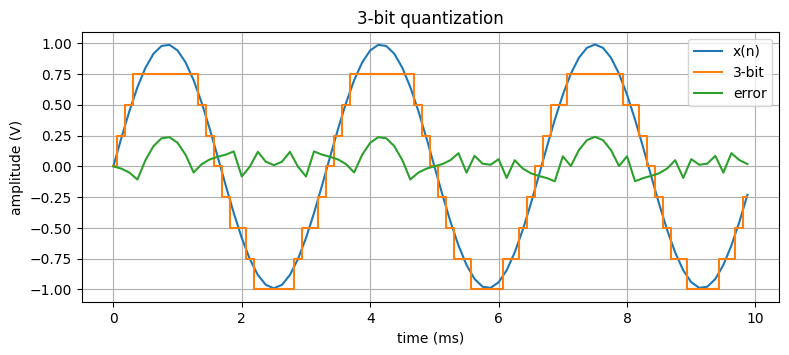

step size delta = 0.25 V
max |error| = 0.24 V


In [21]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits            # step size
    q = np.round(x/delta)*delta               # round to nearest level
    return np.clip(q, -full_scale, full_scale - delta)   # keep inside range

fs = 8000
t = np.arange(0, 0.01, 1/fs)                  # 10 ms = 80 samples
x = 0.99*np.sin(2*np.pi*300*t)                # 300 Hz sine
xq = quantize(x, 3)

plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)"); plt.ylabel("amplitude (V)")
plt.title("3-bit quantization"); plt.grid(True); plt.legend(); plt.show()

print("step size delta =", 2*1.0/2**3, "V")
print("max |error| =", round(np.max(np.abs(x - xq)), 4), "V")

## Task 2.4 — Verify the 6 dB-per-bit rule

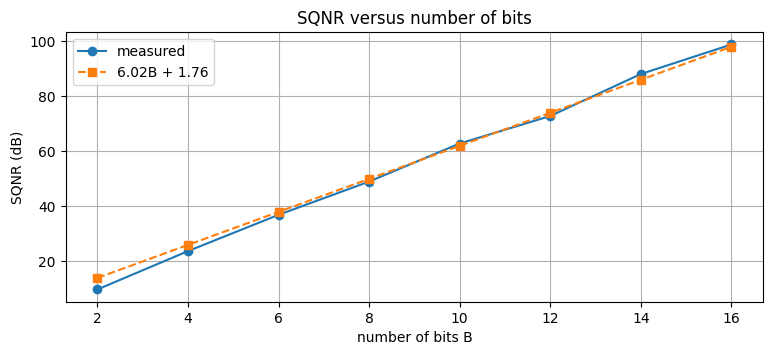

 B | measured (dB) | theory (dB)
 2 |          9.60 |      13.80
 4 |         23.58 |      25.84
 6 |         36.81 |      37.88
 8 |         48.93 |      49.92
10 |         62.81 |      61.96
12 |         72.84 |      74.00
14 |         88.13 |      86.04
16 |         98.91 |      98.08


In [22]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]
theo = 6.02*bits + 1.76

plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, theo, "s--", label="6.02B + 1.76")
plt.xlabel("number of bits B"); plt.ylabel("SQNR (dB)")
plt.title("SQNR versus number of bits")
plt.grid(True); plt.legend(); plt.show()

print(" B | measured (dB) | theory (dB)")
for B, m, th in zip(bits, meas, theo):
    print(f"{B:2d} | {m:13.2f} | {th:10.2f}")

## Task 2.5 — Quantize your voice

In [23]:
import os
from IPython.display import Audio, display

fname = "my_voice.wav"

if os.path.exists(fname):
    fs_v, v = wavfile.read(fname)

    v = v.astype(float)
    if v.ndim > 1:
        v = v.mean(axis=1)

    peak = np.max(np.abs(v))
    if peak > 0:
        v = v / peak

else:
    fs_v = 16000
    tt = np.arange(0, 2, 1/fs_v)
    v = 0.5*np.sin(2*np.pi*440*tt) * np.exp(-tt)

v = 0.99 * v

voice_q = {}

print(" B | SQNR (dB) | sine theory (dB)")

for B in [4, 8, 12]:
    vq = quantize(v, B)
    voice_q[B] = vq

    error = v - vq
    noise_power = np.sum(error**2)
    signal_power = np.sum(v**2)

    sqnr = 10*np.log10(signal_power / noise_power) if noise_power > 0 else float("inf")

    print(f"{B:2d} | {sqnr:9.2f} | {6.02*B + 1.76:10.2f}")

 B | SQNR (dB) | sine theory (dB)
 4 |     13.37 |      25.84
 8 |     37.72 |      49.92
12 |     61.81 |      74.00


In [24]:
from IPython.display import Audio, display

print("Original voice")
display(Audio(v, rate=fs_v))

print("4-bit voice")
display(Audio(voice_q[4], rate=fs_v))

print("8-bit voice")
display(Audio(voice_q[8], rate=fs_v))

print("12-bit voice")
display(Audio(voice_q[12], rate=fs_v))

Original voice


4-bit voice


8-bit voice


12-bit voice
